In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import plotly.graph_objects as go
from matplotlib.ticker import MaxNLocator

# https://matplotlib.org/stable/users/explain/colors/colormaps.html#qualitative


In [2]:
# read and process dataset

path = r"data\src\conflated_database___2026_03_31__11_14_35.xlsx"

df = pd.read_excel(path, sheet_name="TextReading_Included")
df = df[df.topic.notna()].reset_index(drop=True)
df.topic = df.topic.apply(lambda x: x.split(", "))
df.Year = df.Year.astype(int)

df_model = df[df.topic.apply(lambda x: "Model" in x)].reset_index(drop=True)

print(f"papers -- total: {df.shape[0]}")
print(f"papers -- new generative method : {df_model.shape[0]}")

papers -- total: 72
papers -- new generative method : 65


# *SUBSET DATASET COLUMNS*

# MODEL

In [3]:
import matplotlib.colors as mcolors

cmap = plt.cm.Set2
# cmap = plt.cm.Set3
# cmap = plt.cm.Paired
# cmap = plt.cm.Accent
# cmap = plt.cm.tab10
hex_colors = [
    mcolors.to_hex(c)
    for c in cmap.colors
]

print(hex_colors)

['#66c2a5', '#fc8d62', '#8da0cb', '#e78ac3', '#a6d854', '#ffd92f', '#e5c494', '#b3b3b3']


In [4]:
# plots
# MODEL_COLOR_MAP = {
#     'Autoregressive': 'tab:blue',
#     'Diffusion': 'tab:orange',
#     'Discriminative': 'tab:green',
#     'GAN': 'tab:red',
#     'Hybrid: Discriminative': 'tab:purple',
#     'Hybrid: Generative': 'tab:brown',
#     'VAE': 'tab:pink',
# }

# plots
MODEL_COLOR_MAP = {
    'Autoregressive': '#66c2a5',
    'Diffusion': '#fc8d62',
    'Discriminative': '#8da0cb',
    'GAN': '#e78ac3',
    'Hybrid: Discriminative': '#a6d854',
    'Hybrid: Generative': '#ffd92f',
    'VAE': '#e5c494',
}

In [5]:
# preprocessing
def process_model_df(df_model):

    df_model["Discriminative/Generative"] = df_model["Core Generative Paradigm"].apply(lambda x: "Discriminative" if "Discriminative" in x else "Generative")

    df_model["Model"] = \
    df_model["Core Generative Paradigm"].apply(lambda x: 
        "Hybrid: Discriminative" if ("Hybrid" in x and "Discriminative" in x) else 
        (
            "Hybrid: Generative" if "Hybrid" in x else x
        )
    )

    return df_model


def plot_discriminative_vs_generative(df_model):
    counts = df_model.groupby(['Year', 'Discriminative/Generative']).size().unstack(fill_value=0).sort_index()

    totals = counts.sum(axis=0)
    sorted_counts = (
        totals
        .sort_values(ascending=False)
        .index
    )
    counts = counts[sorted_counts]
    counts.columns = [
        f"{publisher} ({totals[publisher]})"
        for publisher in counts.columns
    ]

    # cmap = plt.cm.Set3
    cmap = plt.cm.tab20b
    # cmap = plt.cm.terrain
    num_colors = len(counts.index)
    colors = [
        cmap(i / num_colors) for i in range(num_colors)
    ]

    ax = counts.plot(
        kind='bar',
        stacked=True,
        rot=0,
        ylabel="# papers",
        color=colors,
    )


def plot_model_per_year(df_model):
    counts = df_model.groupby(['Year', 'Model']).size().unstack(fill_value=0).sort_index()
    
    colors = [
        MODEL_COLOR_MAP.get(col, "#cccccc")
        for col in counts.columns
    ]

    totals = counts.sum(axis=0)
    sorted_counts = (
        totals
        .sort_values(ascending=False)
        .index
    )
    counts = counts[sorted_counts]
    cols = counts.columns.to_list()
    counts.columns = [
        f"{publisher} ({totals[publisher]})"
        for publisher in cols
    ]

    ax = counts.plot(
        kind='bar',
        stacked=True,
        rot=0,
        ylabel="# papers",
        color=colors,
    )


def plot_model(df_model):    
    counts = df_model["Model"].value_counts(ascending=True)
    
    
    counts_col = counts.sort_index().index
    colors = [MODEL_COLOR_MAP[m] for m in reversed(counts_col)]

    # colors = [
    #     MODEL_COLOR_MAP.get(col, "#cccccc")
    #     for col in counts.index
    # ]

    ax = counts.plot(kind="barh", color=colors)
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
    ax.set_xlabel("# papers")
    ax.set_ylabel("ML model")

In [6]:
df_model = process_model_df(df_model)

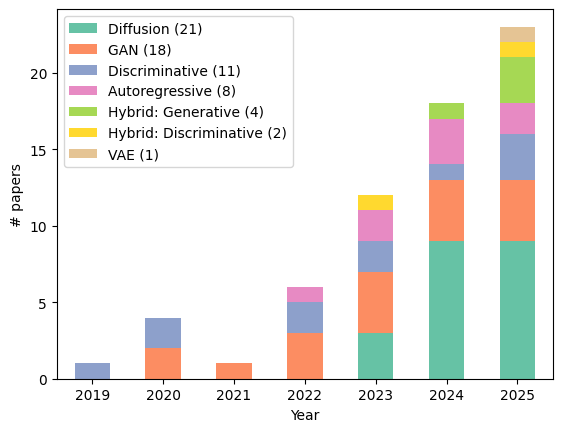

In [7]:
plot_model_per_year(df_model)

In [10]:
# plot_model(df_model)

In [169]:
# plot_discriminative_vs_generative(df_model)

# PRE PROCESSING

In [8]:
def _split_levels(x):
    if ':' in x:
        l1, l2 = x.split(':', 1)
        return pd.Series([l1.strip(), l2.strip()])
    else:
        return pd.Series([x.strip(), None])


def two_level_barh(df, col, xlabel=None, ylabel=None):

    df[f"M_{col}"] = df[col].apply(lambda x: x.split(", "))

    exploded = df[f"M_{col}"].explode()
    exploded = exploded.apply(_split_levels)
    exploded.columns = ['Level1', 'Level2']

    # exploded['Level2'] = exploded['Level2'].fillna('Absent')
    exploded = exploded[exploded["Level1"] != "Absent"]
    # print(exploded)

    counts = exploded.groupby(['Level1', 'Level2']).size().unstack(fill_value=0)
    totals = counts.sum(axis=1)
    counts = counts.loc[totals.sort_values(ascending=True).index]
    
    # cmap = plt.cm.Set2
    # num_colors = len(counts.index)
    # colors = [
    #     cmap(i / num_colors) for i in range(num_colors)
    # ]

    ax = counts.plot(
        kind='barh',
        stacked=True,
        rot=0,
        # color=colors,
        # figsize=(2.5, 5)
    )

    if xlabel is not None:
        plt.xlabel(xlabel)
    if ylabel is not None:
        plt.ylabel(ylabel)

    ax.xaxis.set_major_locator(MaxNLocator(integer=True))

    return ax

<Axes: xlabel='# papers', ylabel='(a) Pre-processing technique'>

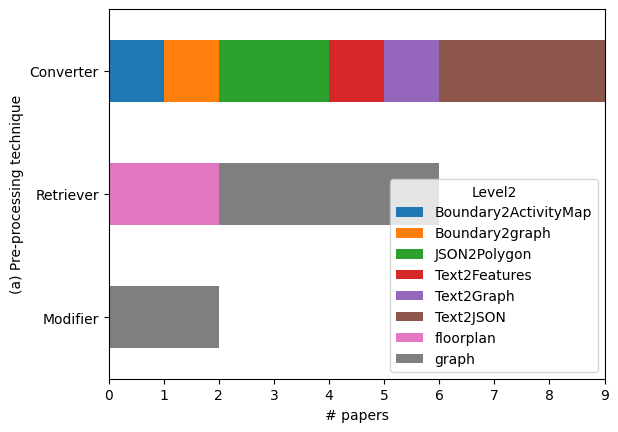

In [9]:
two_level_barh(df_model, "Pre processing outside generative model", xlabel="# papers", ylabel="(a) Pre-processing technique")

# POST PROCESSING

In [11]:
def plot_postprocessing(df_model):
    df_model["postprocessing"] = df_model["Post processing outside generative model"].apply(lambda x: x.split(", "))
    counts = df_model["postprocessing"].explode().value_counts(ascending=True)
    counts = counts.drop("Absent")

    # cmap = plt.cm.tab20
    cmap = plt.cm.tab20c
    # cmap = plt.cm.Set3
    num_colors = len(counts.index)
    colors = [
        cmap(i / num_colors) for i in range(num_colors)
    ]

    ax = counts.plot(
        kind="bar", 
        xlabel="# papers", 
        ylabel="(b) Post-processing technique",
        color=colors,
        # figsize=(2.5, 5),
        rot=0,

    )

    ax.xaxis.set_major_locator(MaxNLocator(integer=True))

    return ax

<Axes: xlabel='# papers', ylabel='(b) Post-processing technique'>

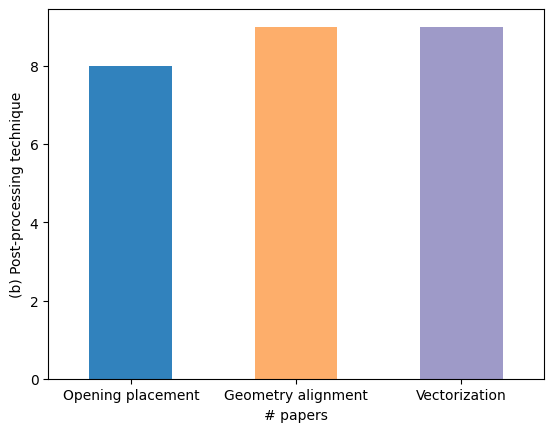

In [12]:
plot_postprocessing(df_model)

# PRE POST

In [13]:
def plot_pre_post_processing(df_model):

    fig, ax = plt.subplots(1, 2, sharey=True, figsize=(10, 5))

    col = "Pre processing outside generative model"
    df_model[f"M_{col}"] = df_model[col].apply(lambda x: x.split(", "))

    exploded = df_model[f"M_{col}"].explode()
    exploded = exploded.apply(_split_levels)
    exploded.columns = ['Level1', 'Level2']
    exploded = exploded[exploded["Level1"] != "Absent"]

    counts = exploded.groupby(['Level1', 'Level2']).size().unstack(fill_value=0)
    totals = counts.sum(axis=1)
    counts = counts.loc[totals.sort_values(ascending=True).index]

    # cmap = plt.cm.Set2
    # num_colors = len(counts.index)
    # colors = [
    #     cmap(i / num_colors) for i in range(num_colors)
    # ]

    counts.plot(
        kind='bar',
        stacked=True,
        rot=45,
        ax=ax[0]
    )

    ax[0].set_ylim(
        0,
        10 * 1,
    )
    ax[0].set_xlabel("")
    ax[0].set_ylabel("# papers")
    ax[0].set_title("(a) Pre-processing")

    df_model["postprocessing"] = df_model["Post processing outside generative model"].apply(lambda x: x.split(", "))
    counts = df_model["postprocessing"].explode().value_counts(ascending=True)
    counts = counts.drop("Absent")

    # cmap = plt.cm.tab20
    cmap = plt.cm.tab20c
    # cmap = plt.cm.Set3
    num_colors = len(counts.index)
    colors = [
        cmap(i / num_colors) for i in range(num_colors)
    ]

    counts.plot(
        kind="bar", 
        color=colors,
        rot=45,
        ax=ax[1]
    )

    ax[1].set_ylim(
        0,
        10 * 1,
    )
    ax[1].set_xlabel("")
    ax[1].set_ylabel("# papers")
    ax[1].set_title("(b) Post-processing")



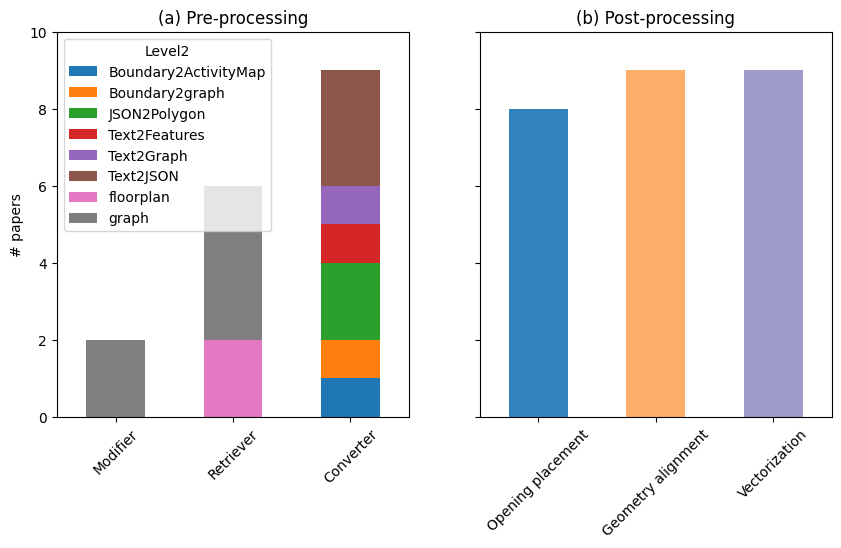

In [14]:
plot_pre_post_processing(df_model)

# INPUT

In [15]:
def preprocess_input(df_model):
    df_model["input"] = df_model["Neural Input (modality: semantics)"].apply(lambda x: set(x.split(", ")))
    df_model["input_modality"] = df_model["input"].apply(lambda x: set(i.split(": ")[0] for i in x))
    df_model["input_content"] = df_model["input"].apply(lambda x: set(i.split(": ")[1] for i in x if i != "Absent")) ### to check later !!!
    return df_model


def plot_input_modality(df_model, ax=None):

    counts = df_model["input_modality"].explode().value_counts(ascending=True)

    cmap = plt.cm.tab20
    num_colors = len(counts.index)
    colors = [
        cmap(i / num_colors) for i in range(num_colors)
    ]

    counts.plot(
        kind="barh", 
        xlabel="# papers", 
        ylabel="Input modality",
        color=colors,
        ax=ax,
    )


def plot_input_content(df_model, ax=None):

    counts = df_model["input_content"].explode().value_counts(ascending=True)

    cmap = plt.cm.tab20
    num_colors = len(counts.index)
    colors = [
        cmap(i / num_colors) for i in range(num_colors)
    ]

    counts.plot(
        kind="barh", 
        xlabel="# papers", 
        ylabel="Input content",
        color=colors,
        ax=ax,
    )


def get_csv_modality_content(df_model):
    levels = df_model["input"].explode().str.split(':', n=1, expand=True)
    levels.columns = ['level1', 'level2']

    # Clean whitespace
    levels = levels.apply(lambda col: col.str.strip())

    # Count co-occurrences
    counts = (
        levels
        .groupby(['level1', 'level2'])
        .size()
        .reset_index(name='count')
    )

    # Export
    counts.to_csv("data/results/input_modality_content.csv", index=False)


def plot_sankey_input(df_model):

    get_csv_modality_content(df_model)

    df_coocurence = pd.read_csv("data/results/input_modality_content.csv")

    # Keep only needed columns
    df_coocurence = df_coocurence[["level1", "level2", "count"]]

    # Optional: remove tiny flows if diagram is too crowded
    # df = df[df["Count"] >= 2]

    sources = df_coocurence["level1"].astype(str)
    targets = df_coocurence["level2"].astype(str)
    values = df_coocurence["count"]

    # Create unique node list
    nodes = pd.Index(pd.concat([sources, targets]).unique())

    # Map labels to numeric IDs
    source_ids = sources.map(nodes.get_loc)
    target_ids = targets.map(nodes.get_loc)

    fig = go.Figure(data=[go.Sankey(
        node=dict(
            label=nodes.tolist(),
            pad=15,
            thickness=18
        ),
        link=dict(
            source=source_ids,
            target=target_ids,
            value=values
        )
    )])

    fig.update_layout(
        title_text="Modality → Content",
        # font_size=16,
        # font_size=24,
        font_size=20,
        width=1200,
        height=800
    )

    fig.write_image(
        "data/results/input_modality_content.svg",
        scale=4,
    )


In [16]:
df_model = preprocess_input(df_model)

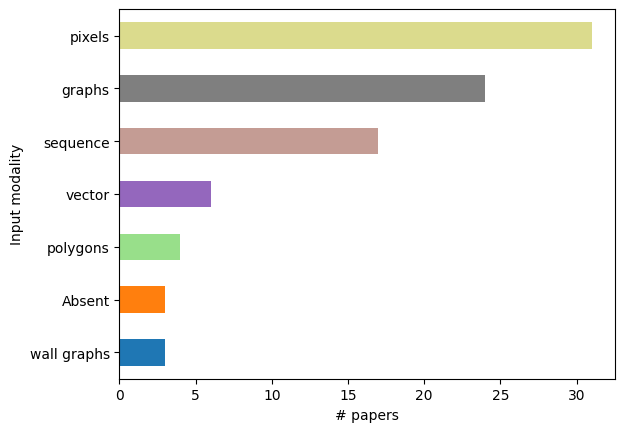

In [17]:
plot_input_modality(df_model)

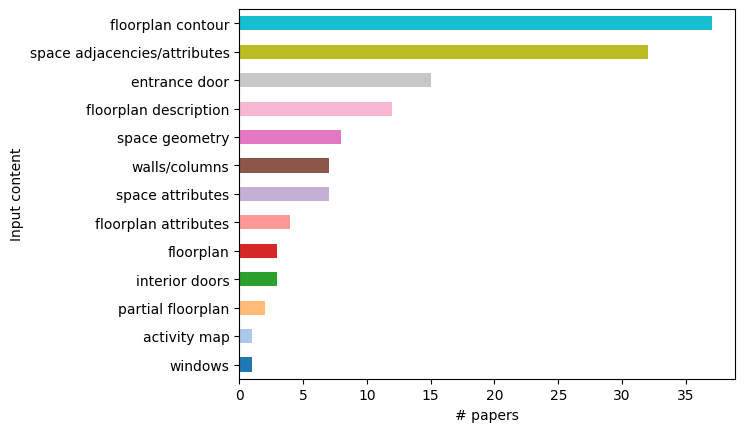

In [18]:
plot_input_content(df_model)

In [19]:
plot_sankey_input(df_model)

# OUTPUT

In [19]:
def plot_output_modality(df_model, ax=None):
    df_model["output_modality"] = df_model["Neural Output (modality)"].apply(lambda x: x.split(", "))
    counts = df_model["output_modality"].explode().value_counts(ascending=True)

    cmap = plt.cm.Set3
    num_colors = len(counts.index)
    colors = [
        cmap(i / num_colors) for i in range(num_colors)
    ]

    counts.plot(
        kind="barh", 
        xlabel="# papers", 
        ylabel="Output modality",
        color=colors,
        ax=ax,
    )



def plot_output_content(df_model, ax=None):
    df_model["output_content"] = df_model["Ultimate Output semantics"].apply(lambda x: set(x.split(", ")))
    counts = df_model["output_content"].explode().value_counts(ascending=True)

    cmap = plt.cm.Set3
    num_colors = len(counts.index)
    colors = [
        cmap(i / num_colors) for i in range(num_colors)
    ]

    counts.plot(
        kind="barh", 
        xlabel="# papers", 
        ylabel="Output content",
        color=colors,
        ax=ax,
    )


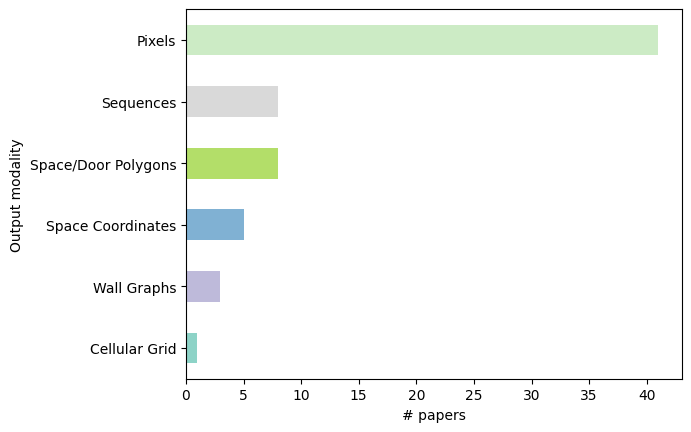

In [20]:
plot_output_modality(df_model)

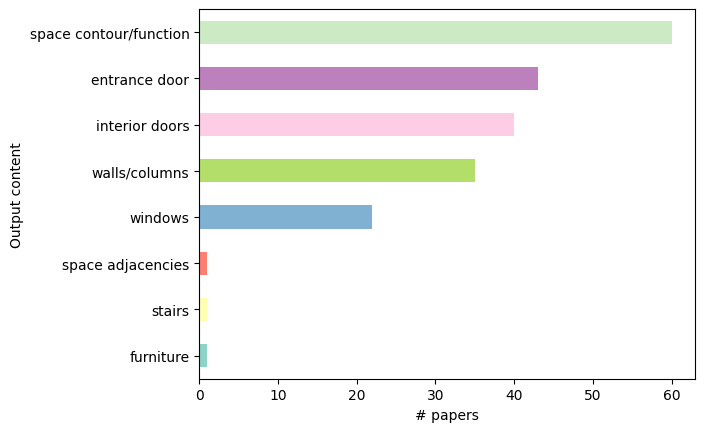

In [21]:
plot_output_content(df_model)

# INPUT-OUTPUT

In [22]:
def plot_input_output_modality(df_model):

    fig, ax = plt.subplots(1, 2, sharex=True, figsize=(8, 4))
    
    plot_input_modality(df_model, ax=ax[0])
    plot_output_modality(df_model, ax=ax[1])

    ax[0].set_title("(a)", fontsize=11)
    ax[1].set_title("(b)", fontsize=11)

    plt.tight_layout()
    plt.show()


def plot_input_output_content(df_model):

    fig, ax = plt.subplots(1, 2, sharex=True, figsize=(9, 4))
    
    plot_input_content(df_model, ax=ax[0])
    plot_output_content(df_model, ax=ax[1])

    ax[0].set_title("(a)", fontsize=11)
    ax[1].set_title("(b)", fontsize=11)

    plt.tight_layout()
    plt.show()

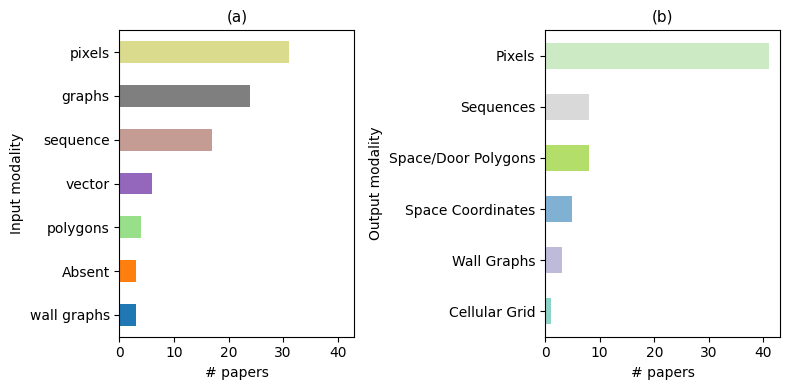

In [23]:
plot_input_output_modality(df_model)

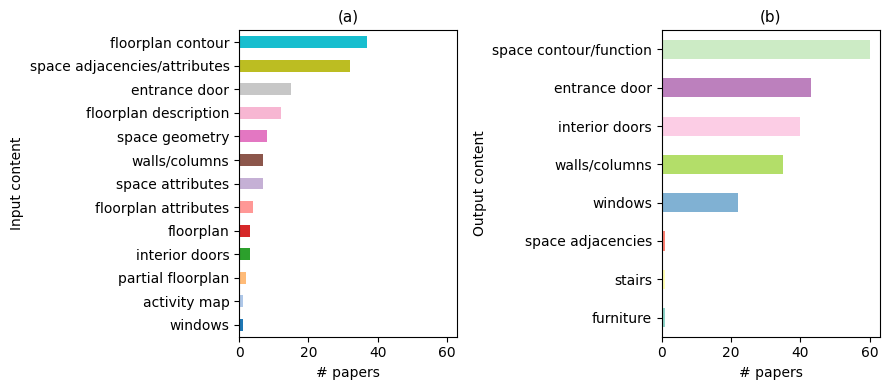

In [25]:
plot_input_output_content(df_model)

In [20]:
cooc_df = pd.read_csv("cooc.csv")
cooc_df

,Unnamed: 0,input_semantics,output_semantics,Count
0,38,space adjacencies/attributes,entrance door + interior doors + space contour...,5
1,41,space adjacencies/attributes,space contour/function,4
2,11,building contour + entrance door + space adjac...,entrance door + interior doors + space contour...,3
3,25,building contour + space contour/BB/center/cen...,entrance door + interior doors + space contour...,3
4,8,building contour + entrance door + floorplan a...,entrance door + interior doors + space contour...,2
5,5,building contour + entrance door,entrance door + interior doors + space contour...,2
6,43,space adjacencies/attributes + walls/columns,space contour/function + walls/columns,2
7,18,building contour + natural language,entrance door + space contour/function,2
8,35,natural language,space contour/function,2
9,39,space adjacencies/attributes,entrance door + interior doors + space contour...,2


# *FULL DATASET COLUMNS*

# DATASET

In [10]:
def merge_datasets(x):
    groups = ["LIFULL", "RPLAN", "GeLayout", "MSD", "Tell2Design"]
    return x if x in groups else "other dataset"


def plot_dataset_per_year(df):

    df["dataset"] = df["Dataset"].apply(lambda x: x.split(", "))

    dataset_exploded = df.explode("dataset")
    dataset_exploded["dataset_grouped"] = dataset_exploded["dataset"].apply(merge_datasets)

    counts = (
        dataset_exploded
        .groupby(['Year', 'dataset_grouped'])
        .size()
        .unstack(fill_value=0)
    )
    y_lim = counts.values.max()*2

    totals = counts.sum(axis=0)
    sorted_counts = (
        totals
        .sort_values(ascending=False)
        .index
    )
    counts = counts[sorted_counts]
    counts.columns = [
        f"{publisher} ({totals[publisher]})"
        for publisher in counts.columns
    ]

    # cmap = plt.cm.Set3
    cmap = plt.cm.tab20c
    num_colors = len(counts.index)
    colors = [
        cmap(i / num_colors) for i in range(num_colors)
    ]

    ax = counts.plot(
        kind='bar',
        stacked=True,
        ylabel='# papers',
        color=colors,
        # figsize=(12,6)
    )
    ax.tick_params(axis='x', rotation=0)
    # ax.grid(axis='y')
    ax.set_ylim(
        0,
        y_lim * 1.1,
    )

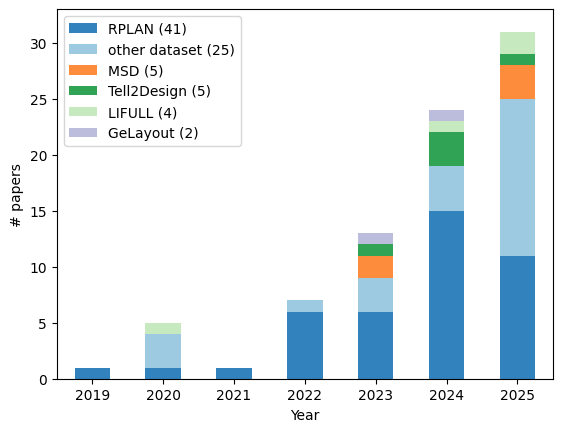

In [10]:
plot_dataset_per_year(df)

# GENERALIZABILITY

In [18]:
def generalizability_barh(df, col, xlabel=None, ylabel=None):

    df[f"M_{col}"] = df[col].apply(lambda x: x.split(", "))

    exploded = df[f"M_{col}"].explode()
    exploded = exploded.apply(_split_levels)
    exploded.columns = ['Level1', 'Level2']

    # exploded['Level2'] = exploded['Level2'].fillna('Absent')
    exploded = exploded[exploded["Level1"] != "Absent"]
    # print(exploded)

    counts = exploded.groupby(['Level1', 'Level2']).size().unstack(fill_value=0)
    totals = counts.sum(axis=1)
    counts = counts.loc[totals.sort_values(ascending=True).index]
    
    # cmap = plt.cm.Set2
    # num_colors = len(counts.index)
    # colors = [
    #     cmap(i / num_colors) for i in range(num_colors)
    # ]

    ax = counts.plot(
        kind='barh',
        stacked=True,
        rot=0,
        # color=colors,
        # figsize=(2.5, 5)
    )
    
    ax.legend(
        loc='center left',
        bbox_to_anchor=(1, 0.5)
    )
    
    if xlabel is not None:
        plt.xlabel(xlabel)
    if ylabel is not None:
        plt.ylabel(ylabel)

    ax.set_xlim(
        0,
        9,
    )

    ax.xaxis.set_major_locator(MaxNLocator(integer=True))

    return ax

<Axes: xlabel='# papers', ylabel='Generalizability/Memorization'>

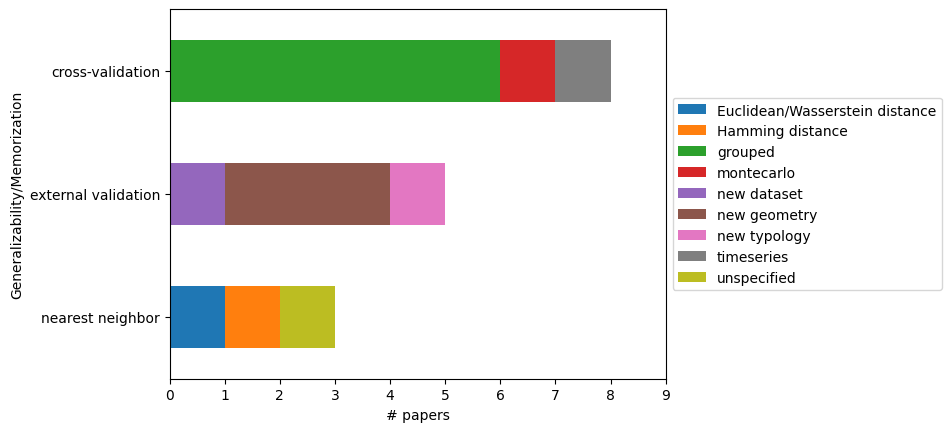

In [19]:
generalizability_barh(df, "Generalizability", xlabel="# papers", ylabel="Generalizability/Memorization")

# USER STUDIES

In [29]:
counts = df["user_studies"].explode().value_counts(ascending=True)
counts


user_studies
Turing test               3
Instruction-following     4
Realism                  17
Intrinsic evaluation     19
Absent                   34
Name: count, dtype: int64

In [33]:
counts.drop("Absent")

user_studies
Turing test               3
Instruction-following     4
Realism                  17
Intrinsic evaluation     19
Name: count, dtype: int64

In [36]:
def plot_user_studies(df):

    df["user_studies"] = df["User Studies"].apply(lambda x: x.split(", "))
    counts = df["user_studies"].explode().value_counts(ascending=True)
    counts = counts.drop("Absent")
    
    cmap = plt.cm.Set3
    # cmap = plt.cm.Pastel1
    # cmap = plt.cm.tab20b
    
    num_colors = len(counts.index)
    colors = [
        cmap(i / num_colors) for i in range(num_colors)
    ]

    ax = counts.plot(
        kind="barh", 
        xlabel="# papers", 
        ylabel="User study type",
        color=colors,
    )

    ax.xaxis.set_major_locator(MaxNLocator(integer=True))

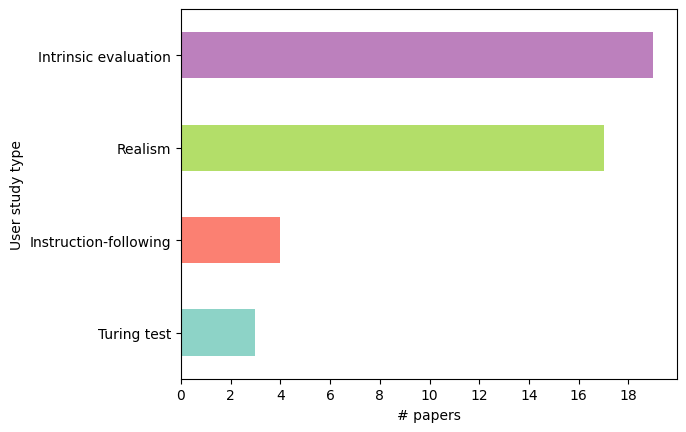

: 

In [ ]:
plot_user_studies(df)

# METRICS

In [297]:
def get_df_metrics(df):
    metric_cols = ["Similarity", "Instruction-Following", "Normative Compliance", "Intrinsic"]
    df_metrics = df[metric_cols]
    for col in metric_cols: 
        df_metrics[col] = df_metrics[col].apply(lambda x: x.split(", "))
    return df_metrics

def _process_list(lst):
    lst = [item.split(": ")[0] for item in lst]
    return set(lst)

def get_df_repr(df):
    df = df.copy()
    for col in df.columns:
        df[col] = df[col].apply(_process_list)
    return df

def get_s_repr(df):
    series = df.apply(lambda row: set.union(*row.values), axis=1)
    series = series.apply(lambda x: x - {'Absent'} if x != {'Absent'} else x)
    return series

def get_matrix(df_repr):
    s_similarity = df_repr["Similarity"].explode().value_counts(ascending=True)
    s_instruction = df_repr["Instruction-Following"].explode().value_counts(ascending=True)
    s_normative = df_repr["Normative Compliance"].explode().value_counts(ascending=True)
    s_intrinsic = df_repr["Intrinsic"].explode().value_counts(ascending=True)

    s_similarity.name = "similarity"
    s_instruction.name = "instriction_following"
    s_normative.name = "normative_compliance"
    s_intrinsic.name = "intrinsic"

    matrix = pd.concat(
        [
            s_similarity,
            s_instruction, 
            s_normative,
            s_intrinsic,
        ], 
        axis=1
    )

    return matrix


"""
Plots
"""
def plot_num_papers_per_repr(s_repr):
    s = s_repr.explode()
    s = s[s != "Absent"]
    counts = s.value_counts(ascending=True)

    color_map = {
        "Embeddings": "#E15759",
        "Regions": "#59A14F",
        "Pixels": "#F28E2B",
        "Attributes": "#4E79A7",
        "Graphs":  "#F5B2D9",
    }
    colors = [color_map.get(label, "#cccccc") for label in counts.index.astype(str)]

    fig, ax = plt.subplots()
    ax.barh(
        counts.index,
        counts,
        color=colors,
    )

    # ax.set_xlabel("# papers")
    # ax.set_ylabel("Metric Group")
    # # ax.grid(axis="x", linestyle="--", alpha=0.4)


def num_papers_per_group(df_repr):
    cols = []
    counts = []
    for col in df_repr.columns:
        count = df_repr[col][df_repr[col] != {'Absent'}].shape[0]
        cols.append(col)
        counts.append(count)

    df = pd.DataFrame({"group": cols, "count": counts})
    df = df.set_index("group")
    df = df.sort_values(by="count", ascending=True)
    # return df

    color_map = {
        "Normative Compliance": "#E15759",
        "Intrinsic": "#59A14F",
        "Instruction-Following": "#F28E2B",
        "Similarity": "#4E79A7",
    }
    colors = [color_map.get(label, "#cccccc") for label in df.index.astype(str)]
    # print (colors)
    
    # fig, ax = plt.subplots(figsize=(6, 4))
    fig, ax = plt.subplots()

    ax.barh(
        df.index,
        df["count"],
        color=colors,
    )

    ax.set_xlabel("# papers")
    ax.set_ylabel("Metric Group")
    # ax.grid(axis="x", linestyle="--", alpha=0.4)


# heatmap
import seaborn as sns

def plot_heatmap(matrix):
    plt.figure(figsize=(8, 5))

    sns.heatmap(
        # matrix,
        matrix.drop("Absent"),
        annot=True,
        fmt=".0f",
        cmap="YlGnBu",
        linewidths=0.5,
        cbar_kws={"label": "# papers"}
    )

    plt.xticks(rotation=45)
    plt.yticks(rotation=0)
    plt.xlabel("Automatic Function Group")
    plt.ylabel("Representation")
    plt.tight_layout()

    plt.show()


def plot_stacked_bars(matrix):
    
    # Replace NaN with 0 for plotting
    matrix_ = matrix.copy()
    matrix_ = matrix_.drop("Absent").fillna(0).T

    # Sort columns by total
    totals = matrix_.sum(axis=1)
    matrix_ = matrix_.loc[totals.sort_values(ascending=True).index]

    ax = matrix_.plot(
        kind="barh",
        stacked=True,
        # figsize=(5, 5),
        # width=0.8,
    )
    
    ax.set_xlabel("# papers")
    ax.set_ylabel("Automatic Function Group")

    ax.legend(
        title="Representation",
        # bbox_to_anchor=(1.02, 0.5),
        # loc="center left"
    )

    # plt.xticks(rotation=45)
    # plt.yticks(rotation=0)
    plt.tight_layout()
    plt.show()



In [236]:
df_metrics = get_df_metrics(df)
df_metrics

,Similarity,Instruction-Following,Normative Compliance,Intrinsic
0,[Absent],[Absent],[Absent],"[Attributes: RAI, Attributes: Space Property P..."
1,"[Pixels: classification performance, Regions: ...",[Absent],[Absent],[Absent]
2,"[Embeddings: FID, Regions: IoU-based]",[Absent],[Absent],[Absent]
3,[Regions: IoU-based],[Absent],[Absent],[Absent]
4,[Embeddings: FID],[Absent],[Absent],[Absent]
...,...,...,...,...
67,"[Graphs: Graph Compatibility, Regions: IoU-based]",[Absent],[Absent],[Absent]
68,[Absent],[Absent],[Absent],[Absent]
69,[Absent],[Absent],[Absent],[Absent]
70,"[Attributes: VGA, Attributes: room statistics]",[Absent],[Absent],[Regions: Percent of isolated rooms]


In [237]:
df_repr = get_df_repr(df_metrics)
df_repr 

,Similarity,Instruction-Following,Normative Compliance,Intrinsic
0,{Absent},{Absent},{Absent},{Attributes}
1,"{Pixels, Regions}",{Absent},{Absent},{Absent}
2,"{Embeddings, Regions}",{Absent},{Absent},{Absent}
3,{Regions},{Absent},{Absent},{Absent}
4,{Embeddings},{Absent},{Absent},{Absent}
...,...,...,...,...
67,"{Regions, Graphs}",{Absent},{Absent},{Absent}
68,{Absent},{Absent},{Absent},{Absent}
69,{Absent},{Absent},{Absent},{Absent}
70,{Attributes},{Absent},{Absent},{Regions}


In [238]:
s_repr = get_s_repr(df_repr)
s_repr

0              {Attributes}
1         {Pixels, Regions}
2     {Embeddings, Regions}
3                 {Regions}
4              {Embeddings}
              ...          
67        {Regions, Graphs}
68                 {Absent}
69                 {Absent}
70    {Regions, Attributes}
71             {Embeddings}
Length: 72, dtype: object

In [239]:
matrix = get_matrix(df_repr)
matrix

,similarity,instriction_following,normative_compliance,intrinsic
Attributes,5,5.0,6.0,4.0
Graphs,7,17.0,1.0,NaN
Absent,13,49.0,65.0,63.0
Pixels,16,NaN,NaN,NaN
Regions,22,4.0,NaN,3.0
Embeddings,40,1.0,NaN,2.0


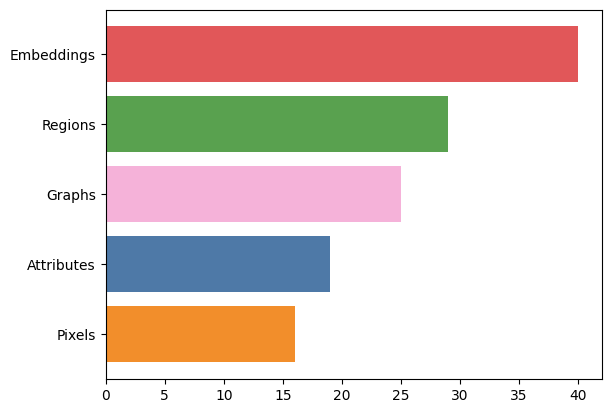

In [240]:
plot_num_papers_per_repr(s_repr)

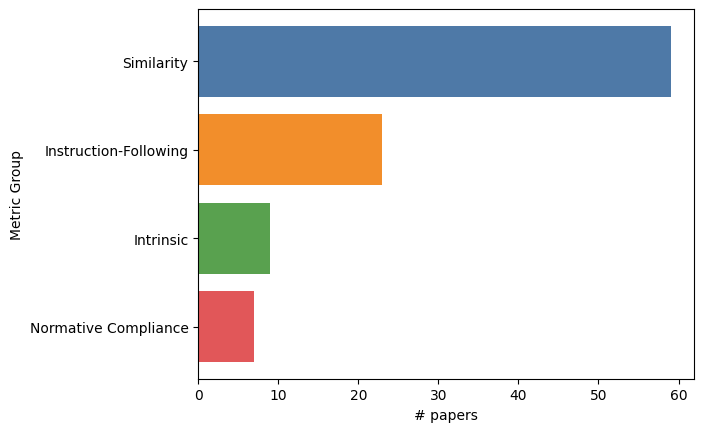

In [241]:
num_papers_per_group(df_repr)

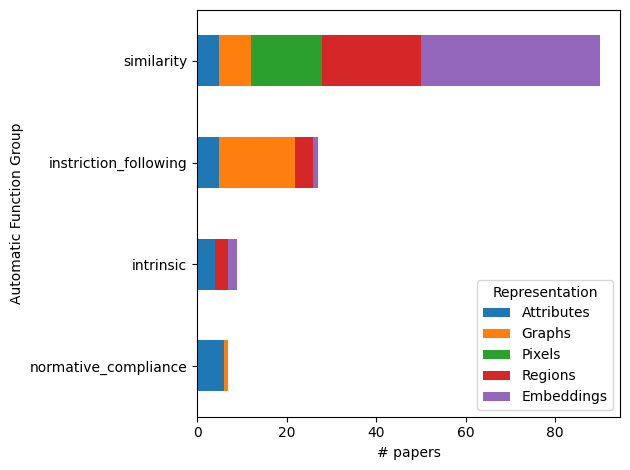

In [296]:
plot_stacked_bars(matrix)

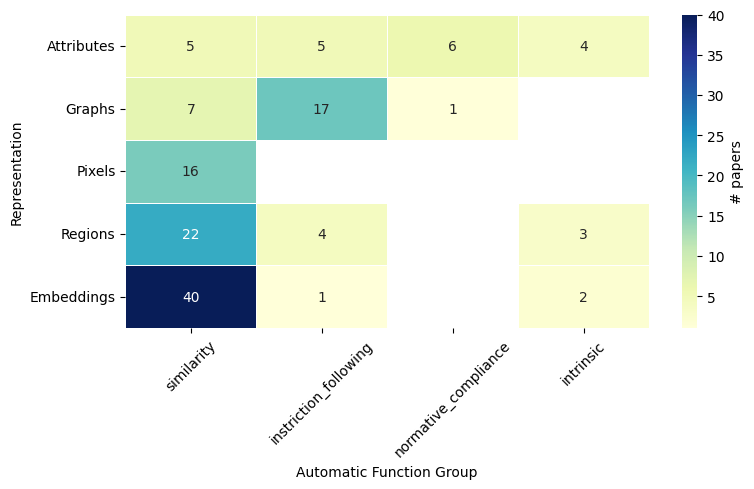

In [243]:
plot_heatmap(matrix)

In [255]:
### individual metrics

def get_s_full(df):
    series = df.apply(lambda row: set.union(*[set(x) for x in row.values]), axis=1)
    series = series.apply(lambda x: x - {'Absent'} if x != {'Absent'} else x)
    return series

def get_unique_metrics(s_full):

    unique_metrics = list(set.union(*s_full.values))
    unique_metrics.remove("Absent")
    
    counts = []
    for metric in unique_metrics:
        count = s_full.apply(lambda x: metric in x).sum()
        counts.append(count)

    df = pd.DataFrame({
        "metric": unique_metrics,
        "counts": counts
    })

    return df


def plot_num_papers_per_metric(df_metrics):

    s_full = get_s_full(df_metrics)
    df_unique = get_unique_metrics(s_full).set_index("metric")
    df_multiple = df_unique[df_unique.counts > 1]
    df_single = df_unique[df_unique.counts == 1]

    s_single = set(df_single.index)
    num_singles = s_full.apply(lambda x: 1 if len(x.intersection(s_single)) > 0 else 0).sum()

    df_multiple.loc["Other metric", "counts"] = num_singles
    df_multiple.index = [x.split(": ")[-1] for x in df_multiple.index]


    print(f"num of unique metrics: {df_unique.shape[0]}")
    print(f"num of one-time-use metrics: {num_singles}")
    print(f"num of reusable metrics: {df_unique.shape[0] - num_singles}")

    counts = df_multiple.sort_values(by="counts", ascending=True)

    # cmap = plt.cm.Set3
    # # cmap = plt.cm.Pastel1
    # # cmap = plt.cm.tab20b
    
    # num_colors = len(counts.index)
    # colors = [
    #     cmap(i / num_colors) for i in range(num_colors)
    # ]

    counts.plot(
        kind="barh", 
        legend=False,
        xlabel="# papers",
        ylabel="Metric",
        # color=colors,
    )

    # return df_multiple

num of unique metrics: 44
num of one-time-use metrics: 17
num of reusable metrics: 27


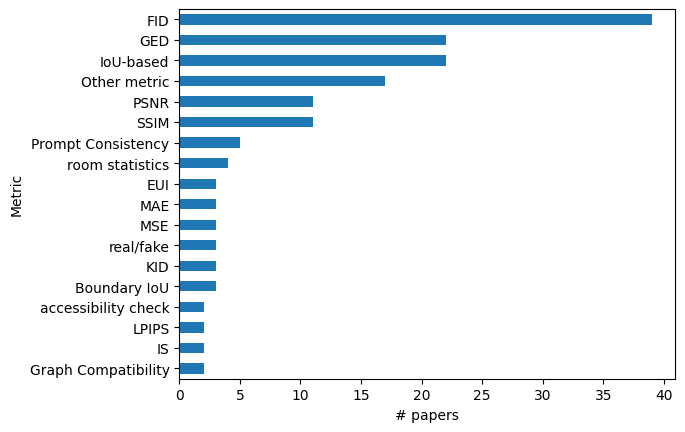

In [257]:
plot_num_papers_per_metric(df_metrics)